# 7. Model Training — XGBoost
Model thứ 2 trong chuỗi so sánh. Train + đánh giá qua Leave-One-Patient-Out (40 fold, ranh giới đã chốt ở bước preprocessing), lưu model từng fold vào `model/checkpoints/xgboost/`, và ghi kết quả vào cùng bảng so sánh chung `model/results/cv_results.csv` để đối chiếu với LightGBM.

## 7.0 Import & cấu hình

In [1]:
import pandas as pd
import numpy as np
import json
import os
import time
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
import gc  

CHECKPOINT_DIR = "../data/checkpoints"
MODEL_DIR = "checkpoints/xgboost"
RESULTS_PATH = "results/cv_results.csv"
MODEL_NAME = "xgboost"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(os.path.dirname(RESULTS_PATH), exist_ok=True)

RISK_ORDER = {"Normal": 0, "Watch": 1, "Alert": 2, "Critical": 3}
CLASS_NAMES = ["Normal", "Watch", "Alert", "Critical"]
RANDOM_STATE = 42

## 7.1 Load checkpoint từ bước preprocessing

In [2]:
dev_df = pd.read_parquet(f"{CHECKPOINT_DIR}/dev_df.parquet")
test_df = pd.read_parquet(f"{CHECKPOINT_DIR}/test_df.parquet")
manifest = json.load(open(f"{CHECKPOINT_DIR}/split_manifest.json"))

FEATURE_COLS = manifest["feature_cols"]
TARGET_COL = manifest["target_col"]
N_FOLDS = manifest["n_folds"]

print(f"dev_df: {dev_df.shape}, test_df: {test_df.shape}, n_folds={N_FOLDS}")

dev_df: (308881, 48), test_df: (60550, 47), n_folds=192


## 7.2 Encode feature & chuẩn bị X/y

In [3]:
def encode_features(d):
    d = d.copy()
    d["risk_level"] = d["risk_level"].map(RISK_ORDER).astype(int)
    return d

dev_enc = encode_features(dev_df)
X_dev = dev_enc[FEATURE_COLS].astype(np.float32)  
y_dev = dev_enc[TARGET_COL].map(RISK_ORDER).astype(int)
fold_id = dev_enc["fold_id"].astype(int)

## 7.3 Hàm ghi kết quả vào bảng so sánh chung
Tái sử dụng nguyên hàm từ notebook LightGBM để đảm bảo `cv_results.csv` có cùng schema, so sánh trực tiếp được giữa các model.

In [4]:
def already_done(results_path, model_name, fold_id):
    if not os.path.exists(results_path):
        return False
    df = pd.read_csv(results_path)
    return ((df["model_name"] == model_name) & (df["fold_id"] == fold_id)).any()

def log_fold_result(results_path, model_name, fold_id, n_val, train_seconds, y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1, 2, 3], zero_division=0
    )
    row = {
        "model_name": model_name, "fold_id": fold_id, "n_val": n_val,
        "train_seconds": round(train_seconds, 2),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }
    for i, cls in enumerate(CLASS_NAMES):
        row[f"precision_{cls}"] = precision[i]
        row[f"recall_{cls}"] = recall[i]
        row[f"f1_{cls}"] = f1[i]
        row[f"support_{cls}"] = support[i]

    df_row = pd.DataFrame([row])
    header = not os.path.exists(results_path)
    df_row.to_csv(results_path, mode="a", header=header, index=False)
    return row

## 7.4 Vòng lặp LOPO: train + lưu model + ghi kết quả

In [5]:
MAX_WEIGHT_RATIO = 100 

XGB_PARAMS = dict(
    objective="multi:softprob", num_class=4,   
    n_estimators=500, learning_rate=0.05, max_depth=6,
    tree_method="hist", eval_metric="mlogloss",
    early_stopping_rounds=30,
    random_state=RANDOM_STATE, verbosity=0,
)

oof_pred = np.full(len(dev_enc), -1)
oof_proba = np.full((len(dev_enc), 4), np.nan) 

for k in range(N_FOLDS):
    tr_mask = fold_id != k
    va_mask = fold_id == k
    fold_model_path = f"{MODEL_DIR}/fold_{k}.json"

    if os.path.exists(fold_model_path) and already_done(RESULTS_PATH, MODEL_NAME, k):
        booster = xgb.Booster()
        booster.load_model(fold_model_path)
        proba = booster.predict(xgb.DMatrix(X_dev[va_mask]))
        oof_pred[va_mask.values] = np.argmax(proba, axis=1)
        oof_proba[va_mask.values] = proba
        print(f"[SKIP] Fold {k} đã có model + kết quả, khôi phục oof từ checkpoint")
        continue

    X_tr, y_tr = X_dev[tr_mask], y_dev[tr_mask]
    X_va, y_va = X_dev[va_mask], y_dev[va_mask]

    classes = np.unique(y_tr)
    weights = compute_class_weight("balanced", classes=classes, y=y_tr)
    weights = np.clip(weights, None, weights.min() * MAX_WEIGHT_RATIO)  
    sample_weight = y_tr.map(dict(zip(classes, weights)))

    t0 = time.time()
    model = xgb.XGBClassifier(**XGB_PARAMS)
    model.fit(
        X_tr, y_tr, sample_weight=sample_weight,
        eval_set=[(X_va, y_va)],
        verbose=False,
    )
    train_seconds = time.time() - t0

    proba = model.predict_proba(X_va)
    pred = np.argmax(proba, axis=1)
    oof_pred[va_mask.values] = pred
    oof_proba[va_mask.values] = proba

    model.get_booster().save_model(fold_model_path)
    result_row = log_fold_result(RESULTS_PATH, MODEL_NAME, k, va_mask.sum(), train_seconds, y_va, pred)

    print(f"Fold {k}: macro_f1={result_row['macro_f1']:.3f}, "
          f"recall_Critical={result_row['recall_Critical']:.3f}, "
          f"({train_seconds:.1f}s) — đã lưu model + ghi kết quả")
    del model, X_tr, X_va, y_tr, y_va, proba
    gc.collect()

np.save(f"{MODEL_DIR}/oof_proba.npy", oof_proba)

Fold 0: macro_f1=0.363, recall_Critical=0.500, (7.6s) — đã lưu model + ghi kết quả
Fold 1: macro_f1=0.337, recall_Critical=0.250, (51.0s) — đã lưu model + ghi kết quả
Fold 2: macro_f1=0.420, recall_Critical=0.000, (49.0s) — đã lưu model + ghi kết quả
Fold 3: macro_f1=0.473, recall_Critical=0.000, (48.3s) — đã lưu model + ghi kết quả
Fold 4: macro_f1=0.322, recall_Critical=0.146, (9.9s) — đã lưu model + ghi kết quả
Fold 5: macro_f1=0.467, recall_Critical=0.000, (14.1s) — đã lưu model + ghi kết quả
Fold 6: macro_f1=0.499, recall_Critical=0.000, (50.0s) — đã lưu model + ghi kết quả
Fold 7: macro_f1=0.310, recall_Critical=0.000, (50.0s) — đã lưu model + ghi kết quả
Fold 8: macro_f1=0.760, recall_Critical=0.000, (48.9s) — đã lưu model + ghi kết quả
Fold 9: macro_f1=0.586, recall_Critical=0.000, (49.2s) — đã lưu model + ghi kết quả
Fold 10: macro_f1=0.654, recall_Critical=0.000, (32.1s) — đã lưu model + ghi kết quả
Fold 11: macro_f1=0.411, recall_Critical=0.000, (16.1s) — đã lưu model + ghi 

## 7.5 Xem lại kết quả XGBoost vừa ghi (đọc lại từ file chung)

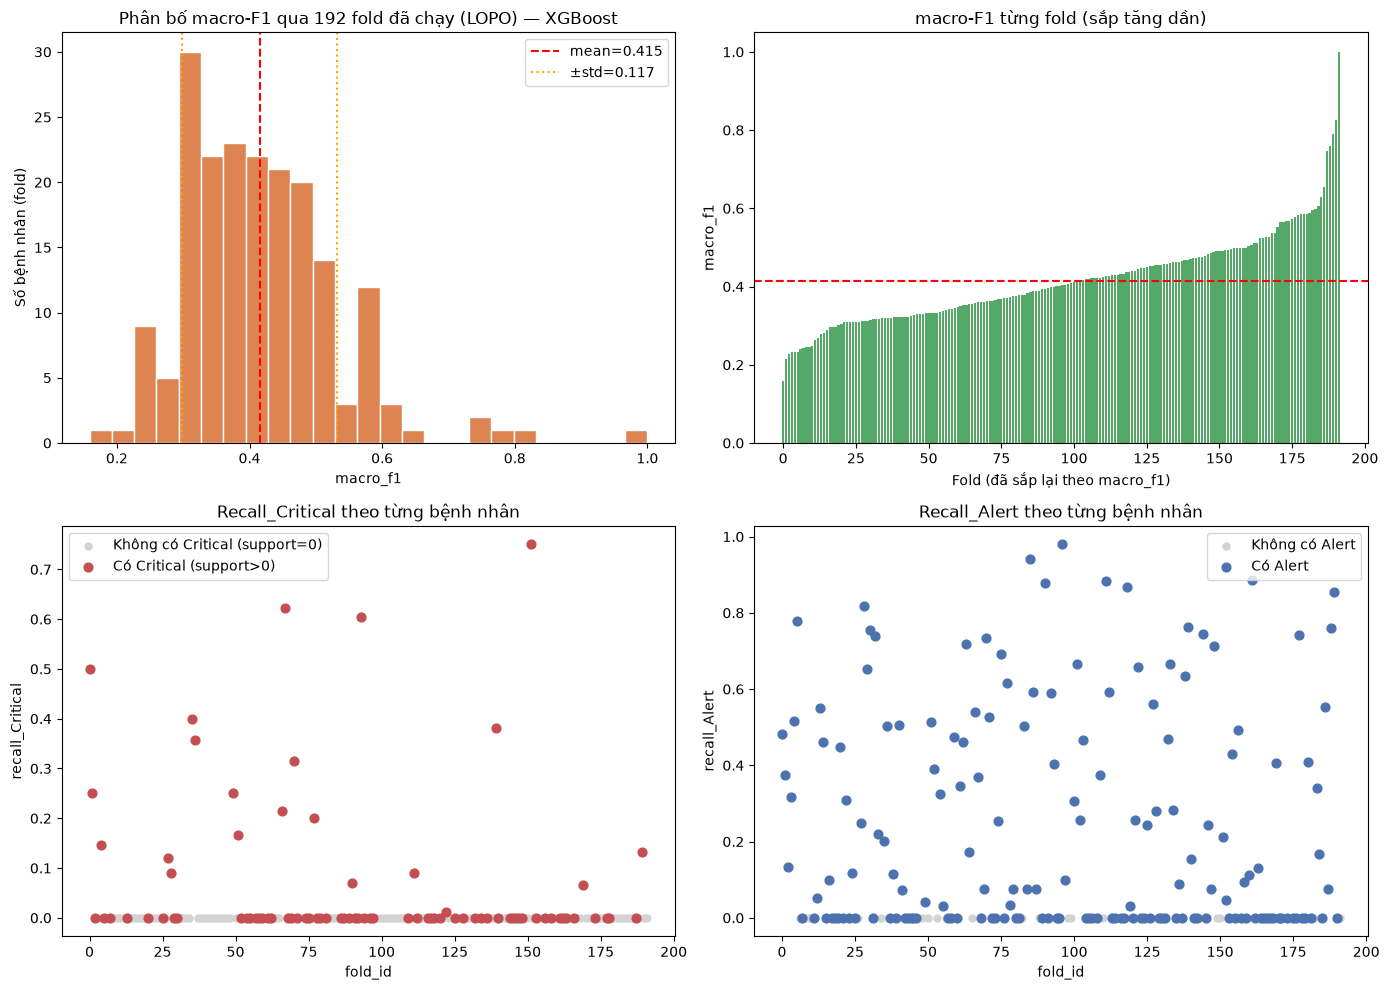

Macro-F1: 0.415 ± 0.117  (192/192 fold đã chạy)
Bệnh nhân có Critical: 81, model bắt được ít nhất 1 ca: 21 (25.9%)


In [6]:
all_results = pd.read_csv(RESULTS_PATH)
xgb_results = all_results[all_results["model_name"] == MODEL_NAME].sort_values("fold_id")

mean_f1, std_f1 = xgb_results["macro_f1"].mean(), xgb_results["macro_f1"].std()
has_critical = xgb_results["support_Critical"] > 0
has_alert = xgb_results["support_Alert"] > 0

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(xgb_results["macro_f1"], bins=25, color="#dd8452", edgecolor="white")
axes[0, 0].axvline(mean_f1, color="red", linestyle="--", label=f"mean={mean_f1:.3f}")
axes[0, 0].axvline(mean_f1 - std_f1, color="orange", linestyle=":", label=f"±std={std_f1:.3f}")
axes[0, 0].axvline(mean_f1 + std_f1, color="orange", linestyle=":")
axes[0, 0].set_title(f"Phân bố macro-F1 qua {len(xgb_results)} fold đã chạy (LOPO) — XGBoost")
axes[0, 0].set_xlabel("macro_f1"); axes[0, 0].set_ylabel("Số bệnh nhân (fold)")
axes[0, 0].legend()

sorted_f1 = xgb_results.sort_values("macro_f1")
axes[0, 1].bar(range(len(sorted_f1)), sorted_f1["macro_f1"], color="#55a868")
axes[0, 1].axhline(mean_f1, color="red", linestyle="--")
axes[0, 1].set_title("macro-F1 từng fold (sắp tăng dần)")
axes[0, 1].set_xlabel("Fold (đã sắp lại theo macro_f1)"); axes[0, 1].set_ylabel("macro_f1")

axes[1, 0].scatter(xgb_results.loc[~has_critical, "fold_id"], xgb_results.loc[~has_critical, "recall_Critical"],
                    color="lightgray", label="Không có Critical (support=0)", s=25)
axes[1, 0].scatter(xgb_results.loc[has_critical, "fold_id"], xgb_results.loc[has_critical, "recall_Critical"],
                    color="#c44e52", label="Có Critical (support>0)", s=40)
axes[1, 0].set_title("Recall_Critical theo từng bệnh nhân")
axes[1, 0].set_xlabel("fold_id"); axes[1, 0].set_ylabel("recall_Critical")
axes[1, 0].legend()

axes[1, 1].scatter(xgb_results.loc[~has_alert, "fold_id"], xgb_results.loc[~has_alert, "recall_Alert"],
                    color="lightgray", label="Không có Alert", s=25)
axes[1, 1].scatter(xgb_results.loc[has_alert, "fold_id"], xgb_results.loc[has_alert, "recall_Alert"],
                    color="#4c72b0", label="Có Alert", s=40)
axes[1, 1].set_title("Recall_Alert theo từng bệnh nhân")
axes[1, 1].set_xlabel("fold_id"); axes[1, 1].set_ylabel("recall_Alert")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/cv_results_overview.png", dpi=120)
plt.show()

n_with_critical = has_critical.sum()
n_detected = (has_critical & (xgb_results["recall_Critical"] > 0)).sum()
print(f"Macro-F1: {mean_f1:.3f} ± {std_f1:.3f}  ({len(xgb_results)}/{N_FOLDS} fold đã chạy)")
if n_with_critical > 0:
    print(f"Bệnh nhân có Critical: {n_with_critical}, model bắt được ít nhất 1 ca: "
          f"{n_detected} ({n_detected/n_with_critical*100:.1f}%)")

In [7]:
worst10 = xgb_results.nsmallest(10, "macro_f1")[
    ["fold_id", "n_val", "macro_f1", "support_Critical", "recall_Critical", "support_Alert", "recall_Alert"]
]
worst10

,fold_id,n_val,macro_f1,support_Critical,recall_Critical,support_Alert,recall_Alert
348,156,345,0.158700,3,0.00,69,0.492754
255,63,524,0.213725,0,0.00,96,0.718750
379,187,1043,0.228427,5,0.00,66,0.075758
288,96,2851,0.233096,166,0.00,2542,0.979150
343,151,667,0.233148,12,0.75,85,0.211765
333,141,1125,0.233902,0,0.00,38,0.000000
260,68,616,0.241604,2,0.00,37,0.000000
273,81,1127,0.241751,2,0.00,9,0.000000
286,94,1243,0.244869,1,0.00,8,0.000000
312,120,2776,0.245355,2,0.00,29,0.000000


## 7.6 Confusion matrix OOF — trực quan hoá

Dùng 192/192 fold đã train xong để vẽ confusion matrix


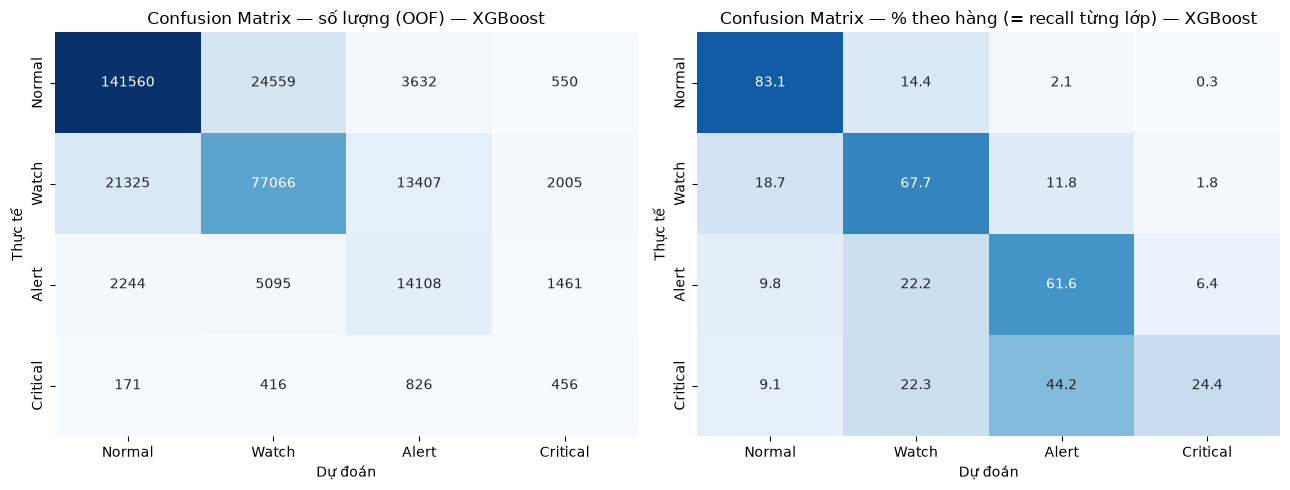

In [8]:
completed_folds = [k for k in range(N_FOLDS) if os.path.exists(f"{MODEL_DIR}/fold_{k}.json")]
print(f"Dùng {len(completed_folds)}/{N_FOLDS} fold đã train xong để vẽ confusion matrix")

oof_pred_cm = np.full(len(dev_enc), -1)
mask_available = np.zeros(len(dev_enc), dtype=bool)

for k in completed_folds:
    va_mask = (fold_id == k).values
    booster = xgb.Booster()
    booster.load_model(f"{MODEL_DIR}/fold_{k}.json")
    proba = booster.predict(xgb.DMatrix(X_dev[va_mask]))
    oof_pred_cm[va_mask] = np.argmax(proba, axis=1)
    mask_available |= va_mask

cm = confusion_matrix(y_dev[mask_available], oof_pred_cm[mask_available], labels=[0, 1, 2, 3])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0], cbar=False)
axes[0].set_title("Confusion Matrix — số lượng (OOF) — XGBoost")
axes[0].set_xlabel("Dự đoán"); axes[0].set_ylabel("Thực tế")
sns.heatmap(cm_norm, annot=True, fmt=".1f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1], cbar=False, vmin=0, vmax=100)
axes[1].set_title("Confusion Matrix — % theo hàng (= recall từng lớp) — XGBoost")
axes[1].set_xlabel("Dự đoán"); axes[1].set_ylabel("Thực tế")
plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/confusion_matrix.png", dpi=120)
plt.show()

## 7.7 Feature importance — bar chart

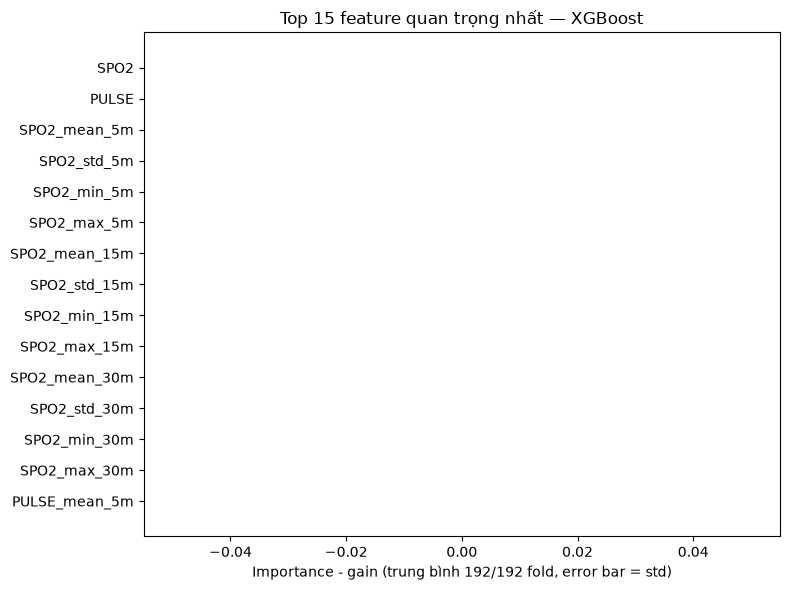

In [9]:
importances = []
for k in completed_folds:
    booster = xgb.Booster()
    booster.load_model(f"{MODEL_DIR}/fold_{k}.json")
    score_dict = booster.get_score(importance_type="gain")
    importances.append([score_dict.get(f"f{i}", 0.0) for i in range(len(FEATURE_COLS))])

importance_df = pd.DataFrame(np.array(importances).T, index=FEATURE_COLS,
                              columns=[f"fold_{k}" for k in completed_folds])
importance_df["mean"] = importance_df.mean(axis=1)
importance_df["std"] = importance_df[[f"fold_{k}" for k in completed_folds]].std(axis=1)

top15 = importance_df.sort_values("mean", ascending=False).head(15)

plt.figure(figsize=(8, 6))
plt.barh(top15.index[::-1], top15["mean"][::-1], xerr=top15["std"][::-1], color="#dd8452")
plt.xlabel(f"Importance - gain (trung bình {len(completed_folds)}/{N_FOLDS} fold, error bar = std)")
plt.title("Top 15 feature quan trọng nhất — XGBoost")
plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/feature_importance.png", dpi=120)
plt.show()

In [10]:
pd.set_option("display.max_rows", 50)
importance_df.sort_values("mean", ascending=False)[["mean", "std"]]

,mean,std
SPO2,0.0,0.0
PULSE,0.0,0.0
SPO2_mean_5m,0.0,0.0
SPO2_std_5m,0.0,0.0
SPO2_min_5m,0.0,0.0
SPO2_max_5m,0.0,0.0
SPO2_mean_15m,0.0,0.0
SPO2_std_15m,0.0,0.0
SPO2_min_15m,0.0,0.0
SPO2_max_15m,0.0,0.0


## 7.8 Model có "biết" Critical nhưng bị argmax che mất không?

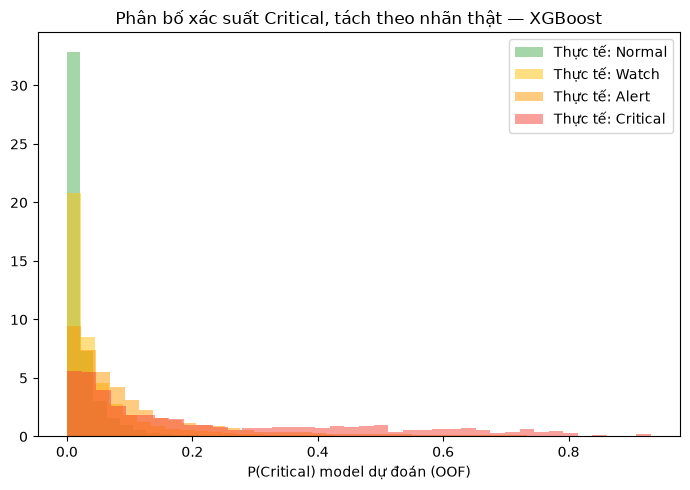

P(Critical) trung bình khi nhãn thật là Critical: 0.243
P(Critical) trung bình khi nhãn thật KHÔNG phải Critical: 0.043


In [11]:
oof_proba_critical = np.full(len(dev_enc), np.nan)

for k in completed_folds:
    va_mask = (fold_id == k).values
    booster = xgb.Booster()
    booster.load_model(f"{MODEL_DIR}/fold_{k}.json")
    proba = booster.predict(xgb.DMatrix(X_dev[va_mask]))
    oof_proba_critical[va_mask] = proba[:, 3]

fig, ax = plt.subplots(figsize=(7, 5))
for cls, color in zip(CLASS_NAMES, ["#4CAF50", "#FFC107", "#FF9800", "#F44336"]):
    mask = (y_dev.values == RISK_ORDER[cls])
    ax.hist(oof_proba_critical[mask], bins=40, alpha=0.5, label=f"Thực tế: {cls}", color=color, density=True)
ax.set_xlabel("P(Critical) model dự đoán (OOF)")
ax.set_title("Phân bố xác suất Critical, tách theo nhãn thật — XGBoost")
ax.legend()
plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/proba_critical_by_true_label.png", dpi=120)
plt.show()

print("P(Critical) trung bình khi nhãn thật là Critical:", oof_proba_critical[y_dev.values == 3].mean().round(3))
print("P(Critical) trung bình khi nhãn thật KHÔNG phải Critical:", oof_proba_critical[y_dev.values != 3].mean().round(3))

## 7.9 Tối ưu ngưỡng quyết định cho Critical (thay vì argmax)

ROC-AUC (Critical vs rest): 0.840   |   Average Precision: 0.076


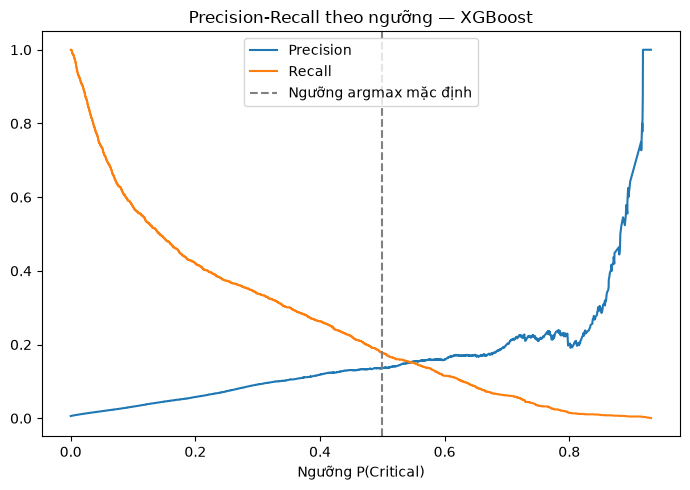

Ngưỡng 0.15: recall=0.489, precision=0.045, bắt 914 ca thật, báo giả 19257 lần
Ngưỡng 0.2: recall=0.420, precision=0.058, bắt 785 ca thật, báo giả 12835 lần
Ngưỡng 0.25: recall=0.373, precision=0.073, bắt 697 ca thật, báo giả 8796 lần
Ngưỡng 0.3: recall=0.339, precision=0.092, bắt 633 ca thật, báo giả 6270 lần
Ngưỡng 0.35: recall=0.301, precision=0.105, bắt 563 ca thật, báo giả 4823 lần


In [12]:
from sklearn.metrics import precision_recall_curve, roc_auc_score, average_precision_score

y_true_binary = (y_dev.values == 3).astype(int)
valid_mask = ~np.isnan(oof_proba_critical)

auc = roc_auc_score(y_true_binary[valid_mask], oof_proba_critical[valid_mask])
ap = average_precision_score(y_true_binary[valid_mask], oof_proba_critical[valid_mask])
print(f"ROC-AUC (Critical vs rest): {auc:.3f}   |   Average Precision: {ap:.3f}")

precisions, recalls, thresholds = precision_recall_curve(y_true_binary[valid_mask], oof_proba_critical[valid_mask])

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(thresholds, precisions[:-1], label="Precision")
ax.plot(thresholds, recalls[:-1], label="Recall")
ax.axvline(0.5, color="gray", linestyle="--", label="Ngưỡng argmax mặc định")
ax.set_xlabel("Ngưỡng P(Critical)")
ax.legend()
ax.set_title("Precision-Recall theo ngưỡng — XGBoost")
plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/critical_threshold_curve.png", dpi=120)
plt.show()

for t in [0.15, 0.20, 0.25, 0.30, 0.35]:
    pred_binary = (oof_proba_critical[valid_mask] >= t).astype(int)
    tp = ((pred_binary == 1) & (y_true_binary[valid_mask] == 1)).sum()
    fp = ((pred_binary == 1) & (y_true_binary[valid_mask] == 0)).sum()
    fn = ((pred_binary == 0) & (y_true_binary[valid_mask] == 1)).sum()
    recall_t = tp / (tp + fn) if (tp+fn) > 0 else 0
    precision_t = tp / (tp + fp) if (tp+fp) > 0 else 0
    print(f"Ngưỡng {t}: recall={recall_t:.3f}, precision={precision_t:.3f}, bắt {tp} ca thật, báo giả {fp} lần")